### Load Data 

In [10]:
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

#"site_category","app_category","device_type"
# "C1", "C14" , "C15", "C16", "C17", "C18", "C19", "C20", "C21"

features= ["banner_pos", "device_type", "C1", "C14" , "C15", "C16", "C17", "C18", "C19", "C20", "C21",]
label="click"

csv_iter = pd.read_csv("./data/train.gz", compression="gzip", iterator=True, chunksize=10000, usecols=features+[label])
#pd.concat([chunk for chunk in csv_iter])
data_train = csv_iter.get_chunk()

df_x_train = data_train[features].dropna()
df_y_train = data_train[label].dropna()

print(df_y_train.value_counts())

x_train = torch.tensor(df_x_train.values).type(torch.double)
y_train = torch.tensor(df_y_train)


x_train, x_test,y_train, y_test = train_test_split(x_train, y_train, train_size=0.8, random_state=42)

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

click
0    8294
1    1706
Name: count, dtype: int64
torch.Size([8000, 11]) torch.Size([8000])
torch.Size([2000, 11]) torch.Size([2000])


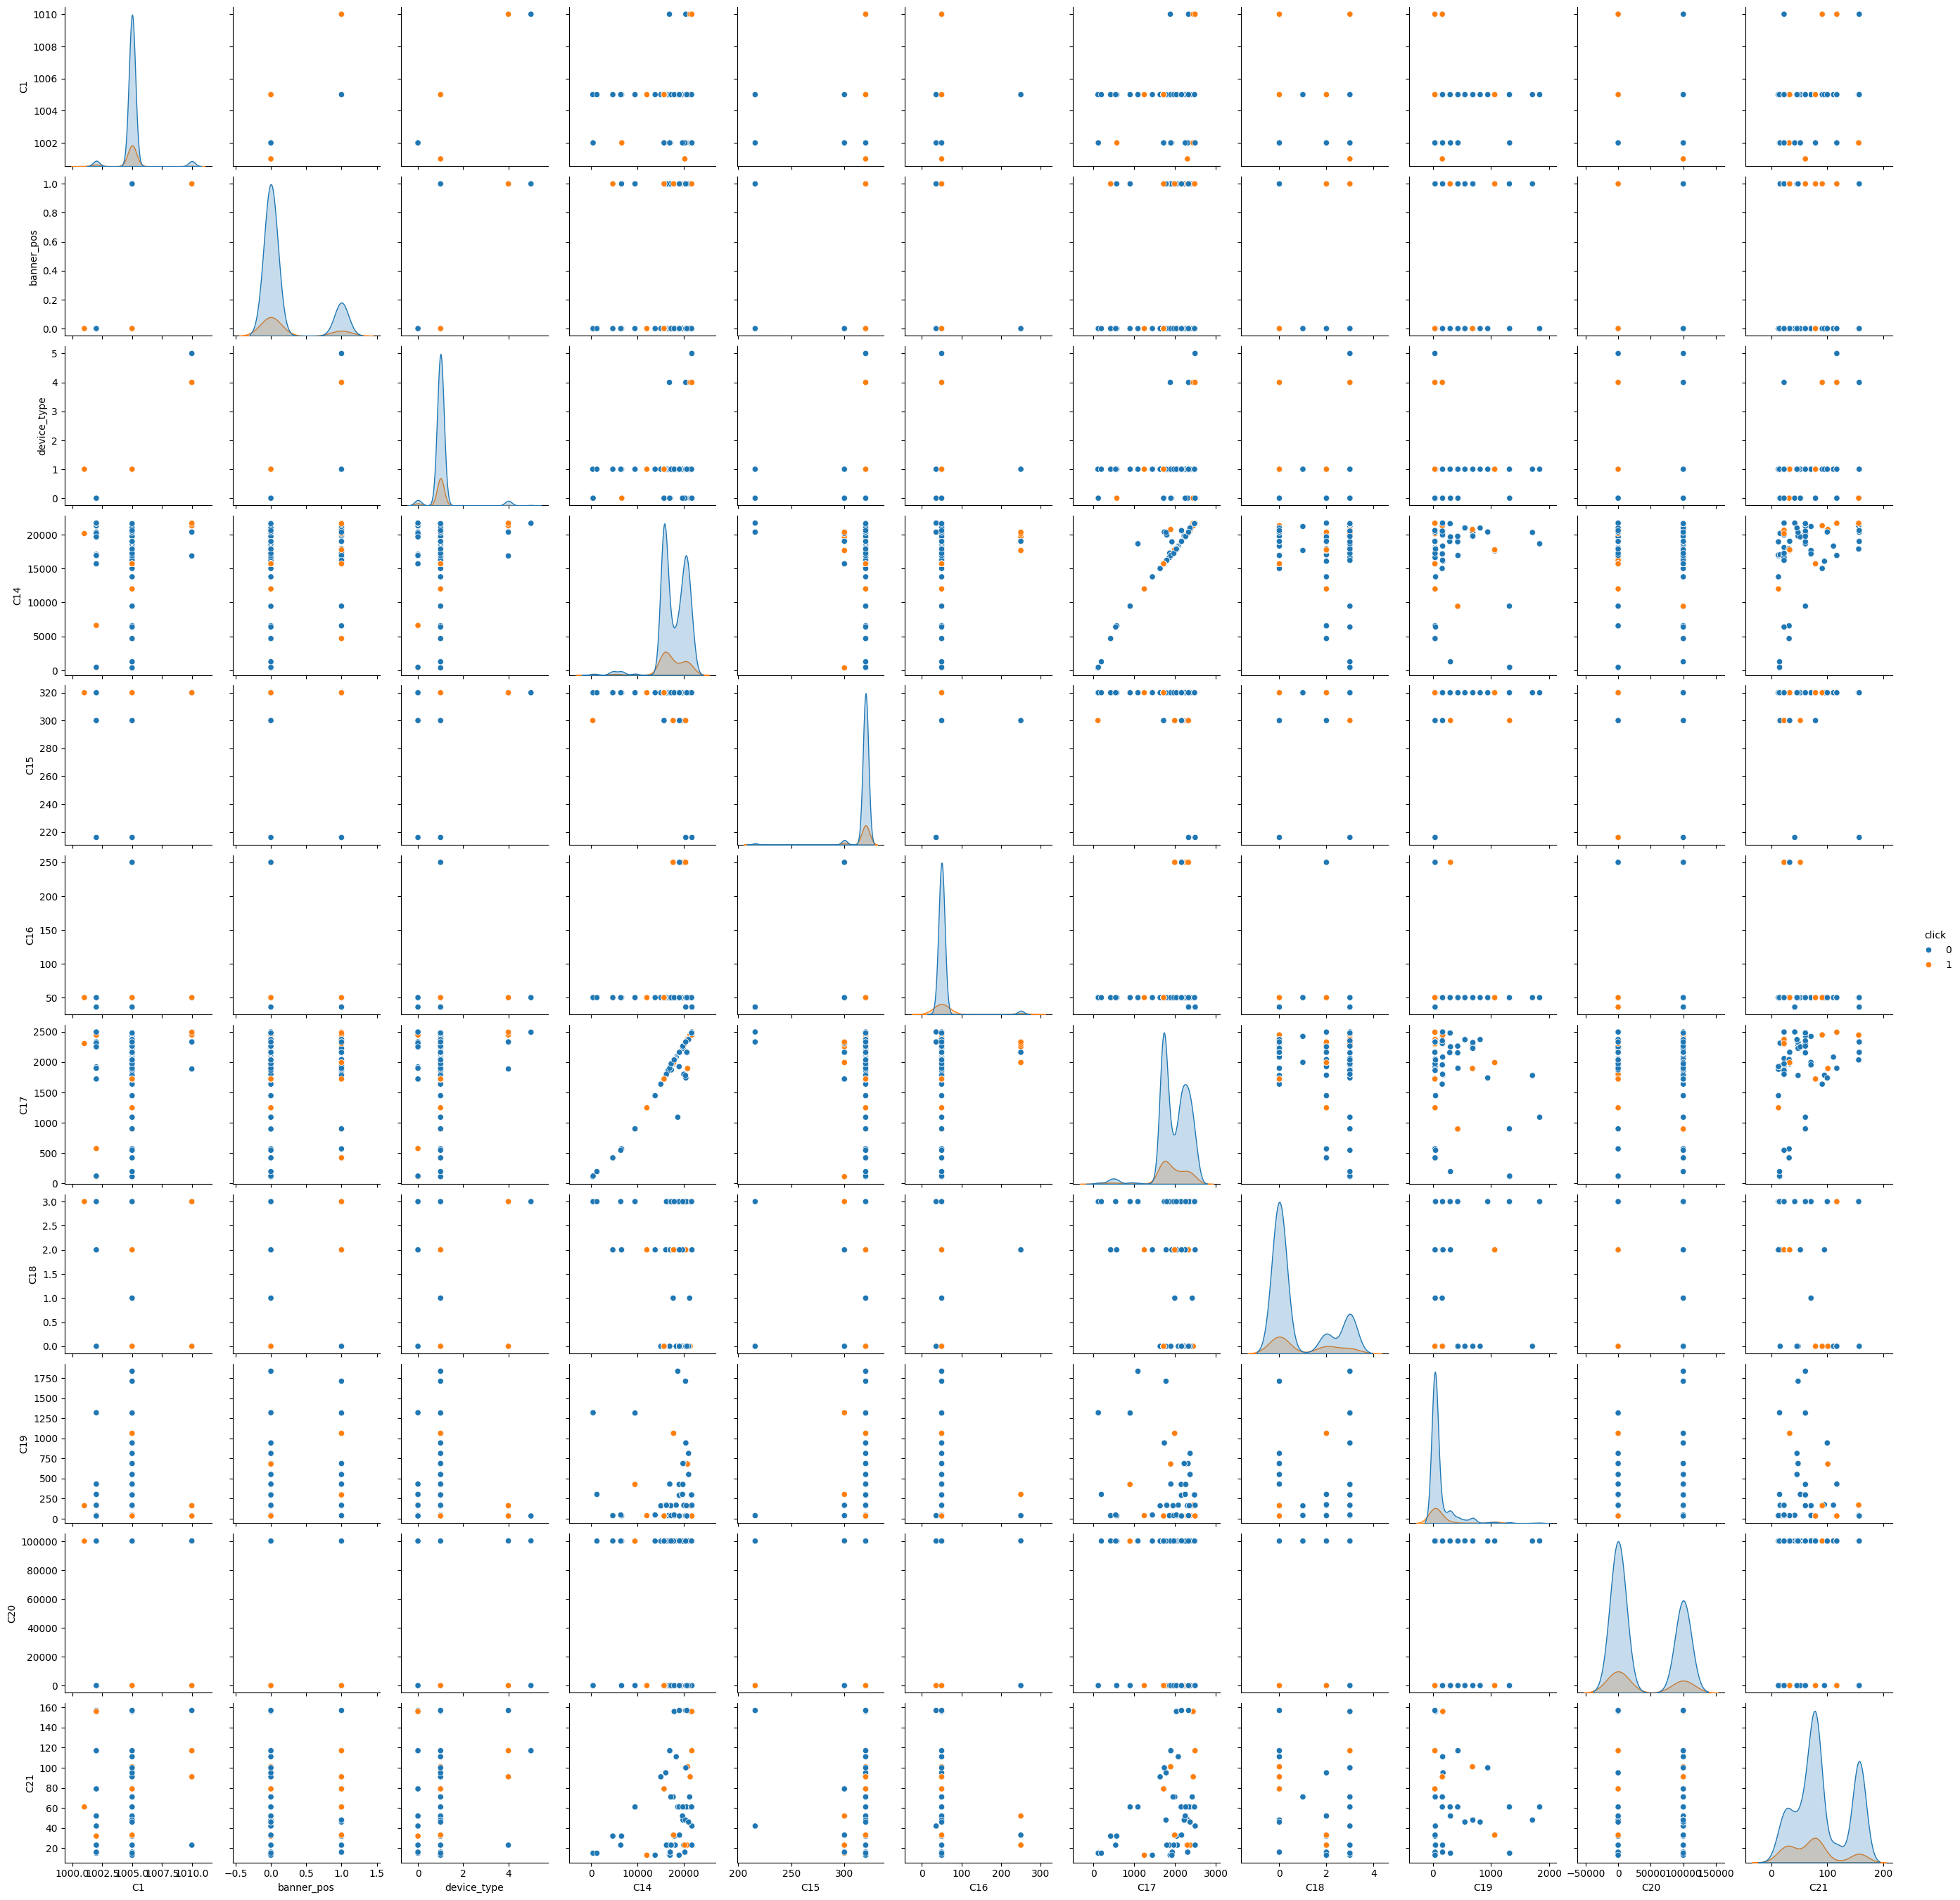

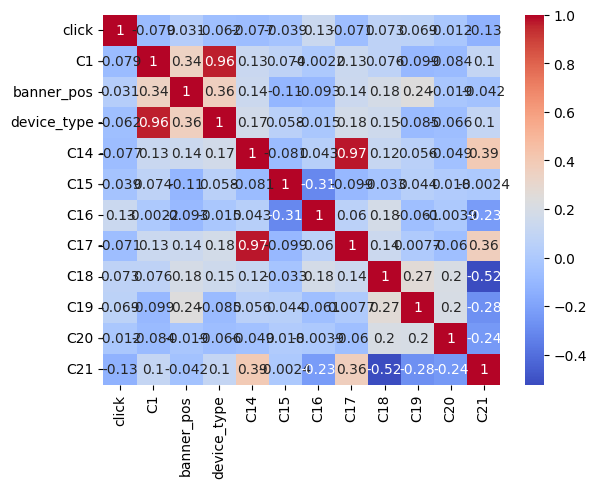

In [11]:
import seaborn as sns
#Brief Exploration of the Dataset
sns.pairplot(data_train[0:1000],hue='click' )
plt.show()
sns.heatmap(data_train[0:1000].corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.show()

### Scale data using standardization

In [12]:
def feature_scaling(X):
    mean = torch.mean(X, dim=0)
    std = torch.std(X, dim=0)
    return (X - mean) / (std + 1e-8)

X_train_scaled = feature_scaling(x_train)
X_test_scaled = feature_scaling(x_test)


# Training the Modell

Note: Changed to mini-batch gradient descent to potenialy increase accuracy and decrease time per epoch


Sigmoid:
$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

In [13]:
def sigmoid(z):
    return 1 / (1 + torch.exp(-z))

Binary Cross-Entropy Loss:
$$
L(y_{\text{true}}, y_{\text{pred}}) = - \frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(y_{\text{pred}, i}) + (1 - y_i) \log(1 - y_{\text{pred}, i}) \right]
$$

In [14]:
def logloss(y_true, y_pred):
    #Avoid log(0)
    epsilon = 1e-7
    y_pred = torch.clamp(y_pred, min=epsilon, max=1 - epsilon)
    return -torch.mean(y_true * torch.log(y_pred) + (1 - y_true) * torch.log(1 - y_pred))

Gradient Calculations with Regularization
$$
\nabla_w L = \frac{1}{N} \sum_{i=1}^{N} x_i \left( \sigma(z_i) - y_i \right) + \frac{\alpha}{N} w
$$

$$
\nabla_b L = \frac{1}{N} \sum_{i=1}^{N} \left( \sigma(z_i) - y_i \right)
$$

In [15]:
def compute_gradients(X_batch, y_batch, w, b, alpha, N):
    y_pred = sigmoid(torch.matmul(X_batch, w) + b)
    dw = torch.mean(X_batch * (y_pred - y_batch).unsqueeze(1), dim=0) + (alpha * w) / N
    db = torch.mean(y_pred - y_batch)

    return dw, db

Model Performance Metrics:
$$
\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}
$$

$$
\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}
$$

In [16]:
def calc_metrics(y_true, y_pred):
    tp = torch.sum((y_true == 1) & (y_pred == 1)).item()
    tn = torch.sum((y_true == 0) & (y_pred == 0)).item()
    fp = torch.sum((y_true == 0) & (y_pred == 1)).item()
    fn = torch.sum((y_true == 1) & (y_pred == 0)).item()

    confusion_matrix = torch.tensor([[tp, fp],
                                     [fn, tn]])
    try:
        precision = tp / (tp + fp)
        recall = tp / (tp + fn)
    except:
        precision = 0
        recall = 0

    return confusion_matrix,precision, recall


Weight & Bias Update:
$$
w := w - \eta \cdot \nabla_w L
$$

$$
b := b - \eta \cdot \nabla_b L
$$

Learning Rate Schedule:
$$
\eta_{\text{new}} = \frac{\eta_0}{1 + k \cdot \text{epoch}}
$$

In [17]:

def initialize_weights(dim):
    w = torch.zeros(dim, dtype=torch.double)
    b = torch.tensor(0.0, dtype=torch.double)
    return w, b


def train(X_train, y_train, X_test, y_test, epochs, alpha, initial_eta, batch_size):
    w, b = initialize_weights(X_train.shape[1])
    N = X_train.shape[0]
    log_loss_train = []
    log_loss_test = []
    confusions = []
    precisions = []
    recalls = []

    for epoch in range(epochs):
        eta = initial_eta / (1 + 0.01 * epoch)

        permutation = torch.randperm(N)
        X_train = X_train[permutation]
        y_train = y_train[permutation]

        for i in range(0, N, batch_size):
            X_batch = X_train[i:i+batch_size]
            y_batch = y_train[i:i+batch_size]

            grad_dw, grad_db = compute_gradients(X_batch, y_batch, w, b, alpha, N)

            w = w - eta * grad_dw
            b = b - eta * grad_db

        # Compute train loss
        y_pred_train = sigmoid(torch.matmul(X_train, w) + b)
        train_loss = logloss(y_train, y_pred_train)
        log_loss_train.append(train_loss.item())

        # Compute test loss
        y_pred_test = sigmoid(torch.matmul(X_test, w) + b)
        test_loss = logloss(y_test, y_pred_test)
        log_loss_test.append(test_loss.item())

        #Calculate Precision, Recall  and Confusion Matrix
        threshold = 0.5
        y_pred_train = (y_pred_train > threshold).int()

        cm, precision, recall = calc_metrics(y_train, y_pred_train)
        confusions.append(cm)
        precisions.append(precision)
        recalls.append(recall)

        if (epoch) % 100 == 0:
            print(f"Epoch [{epoch}/{epochs}] Train Loss: {train_loss:.4f}, Test Loss: {test_loss:.4f}, LR: {eta:.6f} Precision: {precision} Recall {recall}")
            #print(cm)

    return w, b, log_loss_train, log_loss_test, confusions, precisions, recalls

alpha = 0.00001
initial_eta = 0.25
epochs = 1500
batch_size = 32


w, b, log_loss_train, log_loss_test, cm, precision, recall = train(X_train_scaled, y_train,
                                                      X_test_scaled, y_test,
                                                      epochs, alpha, initial_eta, batch_size)

Epoch [0/1500] Train Loss: 0.4414, Test Loss: 0.4231, LR: 0.250000 Precision: 0.5384615384615384 Recall 0.005065123010130246
Epoch [100/1500] Train Loss: 0.4396, Test Loss: 0.4205, LR: 0.125000 Precision: 0.25 Recall 0.000723589001447178
Epoch [200/1500] Train Loss: 0.4384, Test Loss: 0.4211, LR: 0.083333 Precision: 0.25 Recall 0.000723589001447178
Epoch [300/1500] Train Loss: 0.4385, Test Loss: 0.4214, LR: 0.062500 Precision: 0.25 Recall 0.000723589001447178
Epoch [400/1500] Train Loss: 0.4383, Test Loss: 0.4211, LR: 0.050000 Precision: 0.46788990825688076 Recall 0.03690303907380608
Epoch [500/1500] Train Loss: 0.4385, Test Loss: 0.4221, LR: 0.041667 Precision: 0.3333333333333333 Recall 0.000723589001447178
Epoch [600/1500] Train Loss: 0.4384, Test Loss: 0.4213, LR: 0.035714 Precision: 0.48502994011976047 Recall 0.05861070911722142
Epoch [700/1500] Train Loss: 0.4383, Test Loss: 0.4210, LR: 0.031250 Precision: 0.25 Recall 0.000723589001447178
Epoch [800/1500] Train Loss: 0.4382, Test 

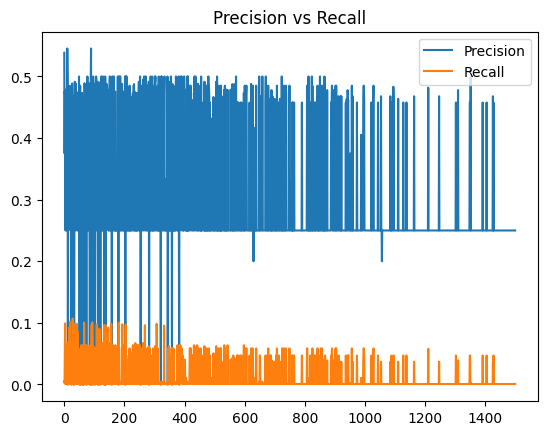

Final Confusion MATRIX

 tensor([[   1,    3],
        [1381, 6615]])


In [18]:

plt.plot(range(len(precision)), precision, label="Precision")
plt.plot(range(len(recall)), recall, label="Recall")
plt.title("Precision vs Recall")
plt.legend()
plt.show()

print("Final Confusion MATRIX\n\n",cm[len(cm)-1])